## =====================================
## Восстанавливаем поля по зашумленным RM
## =====================================

### Векторный потенциал     $A = (0, A_\phi, 0) $ 
 > ↓ $B = Rot(A) = (-\frac{dA_\phi}{dz}, 0, \frac{1}{\rho} \frac{d}{d\rho}(\rho A_\phi))$

### Истинные поля:          ${B_{\phi}}^{true}, {B_{z}}^{true} $
 > ↓ прямая задача 

### Истинная RM:            $B_\phi \rightarrow  RM_{odd} ,\ B_z \rightarrow RM_{even}$, $| RM = RM_{odd} + RM_{even}$
                            
> ↓ добавляем шум на B 

### Зашумлённые поля:       $B_{phi}^{noise}, B_z^{noise}$
> ↓ прямая задача 

### Наблюдаемая RM:         $RM_{odd}^{obs}, RM_{even}^{obs}$  ← вход для обратной задачи 
 > ↓ обратная задача (регуляризация) 

### Восстановленные поля:   $B_\phi^{rec}, B_z^{rec} $
 > ↓ прямая задача

# ---------------------------------------------

In [1]:
# ==============================================================================
# 1: Импорты
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from Magnetic_Field import (
    make_A_phi, A_phi_gaussian, A_phi_uniform, A_phi_power, A_phi_screen,
    compute_B_from_A_phi, extract_axial_profiles,
    save_field_to_csv, load_field_from_csv,
    compute_field_from_B
)
from methods import (
    build_operators, forward_rm, regularizer, RegularizedInversion,
    choose_alpha_lcurve, electron_density, rel_error, relative_error,
    add_noise, plot_recovery, plot_sweep, plot_A_and_B,
    plot_A_phi_profiles, plot_B_profiles, 
    append_run_to_csv, load_runs,
    plot_all_true_fields, plot_all_recovered_fields,
    plot_all_rm, plot_all_rm_noisy,
)

try:
    plt.style.use('seaborn-v0_8-whitegrid')
except OSError:
    plt.style.use('default')

print("✅ Модули загружены.")



✅ Модули загружены.


In [2]:
def Calculate(A_phi_func=None, B_z_func=None, B_rho_func=None, B_phi_func=None,
              mode="from_A",                       # "from_A" | "direct"
              delta=0.05, reg_kind="second_order",
              n_e_model="constant",
              plot=True, filename=None, run_name=None, seed=42,
              wrap_with_A0=True):

    # ==========================================================================
    # Сетка
    # ==========================================================================
    N_rho, N_z = 200, 120
    RHO_MAX, Z_MAX = 15.0, 8.0
    rho_vals = np.linspace(0.05, RHO_MAX, N_rho)
    z_vals   = np.linspace(-Z_MAX, Z_MAX, N_z)

    # ==========================================================================
    # Поле: два режима
    # ==========================================================================
    if mode == "from_A":
        if A_phi_func is None:
            raise ValueError("mode='from_A' требует A_phi_func")
        if wrap_with_A0:
            A_phi_func = make_A_phi(A_phi_func, A0=1.0)
        field = compute_B_from_A_phi(A_phi_func, rho_vals, z_vals)

    elif mode == "direct":
        if B_z_func is None:
            raise ValueError("mode='direct' требует B_z_func")
        field = compute_field_from_B(
            rho_vals,
            B_z_func=B_z_func,
            B_rho_func=B_rho_func,
            B_phi_func=B_phi_func,
        )
    else:
        raise ValueError(f"Неизвестный mode={mode}")

    # ==========================================================================
    # Осевой срез — единый для обоих режимов
    # ==========================================================================
    prof = extract_axial_profiles(field)
    rho        = prof['rho']
    B_z_true   = prof['B_z']
    B_phi_true = prof['B_phi']

    # ==========================================================================
    # Дальше всё как было: физика, RM, шум, восстановление, сохранение
    # ==========================================================================
    K_RM, theta_deg = 1.0, 80.0
    n_e_true = electron_density(rho, model=n_e_model, scale=RHO_MAX/3.0)

    M_z, M_phi = build_operators(rho, K_RM=K_RM, theta_deg=theta_deg, n_quad=400)

    f_z_true   = n_e_true * B_z_true
    f_phi_true = n_e_true * B_phi_true

    RM_even_true, RM_odd_true, RM_total_true = forward_rm(
        M_z, M_phi, f_z_true, f_phi_true)

    RM_even_noisy = add_noise(RM_even_true, delta, seed=seed)
    RM_odd_noisy  = add_noise(RM_odd_true,  delta, seed=seed + 1)

    N = len(rho)
    H_z   = regularizer(N, kind=reg_kind)
    H_phi = regularizer(N, kind=reg_kind)
    inv_z   = RegularizedInversion(M_z,   H_z)
    inv_phi = RegularizedInversion(M_phi, H_phi)

    alphas = np.logspace(-10, 0, 80)
    alpha_z_opt,   _, _ = choose_alpha_lcurve(inv_z,   RM_even_noisy, alphas, label="B_z")
    alpha_phi_opt, _, _ = choose_alpha_lcurve(inv_phi, RM_odd_noisy,  alphas, label="B_phi")

    f_z_rec   = inv_z(RM_even_noisy, alpha_z_opt)
    f_phi_rec = inv_phi(RM_odd_noisy, alpha_phi_opt)

    n_e_safe  = np.where(n_e_true > 1e-10, n_e_true, 1e-10)
    B_z_rec   = f_z_rec   / n_e_safe
    B_phi_rec = f_phi_rec / n_e_safe

    err_B_z   = relative_error(B_z_true,   B_z_rec)
    err_B_phi = relative_error(B_phi_true, B_phi_rec)

    # ==========================================================================
    # Сохранение
    # ==========================================================================
    if filename is not None:
        if run_name is None:
            base = (A_phi_func.__name__ if mode == "from_A"
                    else getattr(B_z_func, '__name__', 'B_direct'))
            run_name = f"{mode}_{base}_d{delta:.3f}"
        append_run_to_csv(filename, run_name, {
            'B_z_true':      B_z_true,
            'B_z_rec':       B_z_rec,
            'B_phi_true':    B_phi_true,
            'B_phi_rec':     B_phi_rec,
            'RM_even_true':  RM_even_true,
            'RM_even_noisy': RM_even_noisy,
            'RM_odd_true':   RM_odd_true,
            'RM_odd_noisy':  RM_odd_noisy,
            'alpha':         np.full_like(rho, alpha_z_opt),
            'delta':         np.full_like(rho, delta),
            'err_Bz':        np.full_like(rho, err_B_z),
        }, rho)

    # ==========================================================================
    # Графики
    # ==========================================================================
    if plot:
        if mode == "from_A":
            plot_A_and_B(field, rho_vals, z_vals)
            plot_A_phi_profiles(field, rho_vals, z_vals)
        plot_B_profiles(field, rho_vals, z_vals)

        plot_recovery(
            rho=rho,
            true_fields=(B_phi_true, B_z_true),
            rec_fields=(B_phi_rec, B_z_rec),
            alphas=(alpha_phi_opt, alpha_z_opt),
            delta=delta,
            trivial_phi=True,
        )

    return {
        'rho': rho,
        'B_z_true': B_z_true, 'B_z_rec': B_z_rec,
        'B_phi_true': B_phi_true, 'B_phi_rec': B_phi_rec,
        'RM_even_true': RM_even_true, 'RM_even_noisy': RM_even_noisy,
        'RM_odd_true': RM_odd_true, 'RM_odd_noisy': RM_odd_noisy,
        'alpha': alpha_z_opt, 'delta': delta,
        'err_Bz': err_B_z, 'err_B_phi': err_B_phi,
        'mode': mode,
    }

### ==============================================================================
### 2: >>> ВЕКТОРНЫЙ ПОТЕНЦИАЛ A_phi <<<
### ==============================================================================


 | type | Потенциал | Ожидаемое B_z |
 |---|---|---|
 | 1 | `A0·ρ` | постоянность |
 | 2 | `A0·ρ²/R` | линейный рост |
 | 3 | `A0·ρ·exp(-ρ/L)` | локальный горб смена знака |

 **Важно про нечётный канал.** Если задан только `A_phi`, то
 `B_phi = rot(A)_phi ≡ 0` тождественно. Поэтому `RM_odd ≡ 0`


In [3]:

def A_phi_gaussian(rho, z, A0=1.0, rho_scale=5.0, z_scale=3.0):
    """A_phi = A0 * rho * exp(-(rho/rho_scale)^2 - (z/z_scale)^2)."""
    return A0 * rho * np.exp(-(rho / rho_scale) ** 2 - (z / z_scale) ** 2)


def A_phi_uniform(rho, z, A0=1.0):
    """A_phi = A0 * rho  ->  однородное B_z = 2*A0."""
    return A0 * rho * np.exp(-z)


def A_phi_power(rho, z, A0=1.0, power=3.0, rho_scale=5.0):
    """A_phi = A0 * rho ^ power """
    return A0 * np.power(rho, power) 

def A_phi_exp(rho, z, A0=1.0, power=2.0, rho_scale=5.0):
    """A_phi = A0 * exp(-rho)."""
    return A0 * np.exp(-rho)




In [4]:
FILENAME = "results/all_runs_var_with A.csv"
# Очистим файл, чтобы не смешивать со старыми запусками
if os.path.exists(FILENAME):
    os.remove(FILENAME)
    
# Список всех вариантов A_phi
variants_A = {
    "uniform":   lambda rho, z, **kw: A_phi_uniform(rho, z, A0=1.0),
    "exp":       lambda rho, z, **kw: A_phi_exp(rho, z, A0=1.0),
    "power2":    lambda rho, z, **kw: A_phi_power(rho, z, A0=1.0, power=2.0, rho_scale=5.0),
}

delta_common = 0.02
# Прогон всех вариантов с одинаковым шумом
for name, func in variants_A.items():
    Calculate(A_phi_func=func, mode="from_A",
              delta= delta_common, plot=False,
              filename=FILENAME, run_name=f"A_{name}", seed=42,
              wrap_with_A0=False)

💾 Запуск 'A_uniform' добавлен в results/all_runs_var_with A.csv
💾 Запуск 'A_exp' добавлен в results/all_runs_var_with A.csv
💾 Запуск 'A_power2' добавлен в results/all_runs_var_with A.csv


In [3]:
deltas = [0, 0.05, 0.1, 0.15, 0.2]

In [ ]:
def B_z_gauss(rho, B0=1.0, rho_scale=5.0):
    return B0 * np.exp(-(rho / rho_scale)**2)

def B_z_local(rho, B0=1.0, rho_scale=5.0):
    # локальный горб со сменой знака — аналог A_phi = ρ·e^(-ρ/L)
    return B0 * (1 - (rho / rho_scale)**2) * np.exp(-(rho / rho_scale)**2)

def B_z_linear(rho, B0=0.1):
    return B0 * rho

variants_B = {
    "B_gauss":  B_z_gauss,
    "B_local":  B_z_local,
    "B_linear": B_z_linear,
}

REG_KIND = "second_order"
reg_kinds = ['second_order']
for REG_KIND in reg_kinds:
    for delta_tmp in deltas:
        FILENAME = f"results/all_runs_var_with B_noise_{delta_tmp}_reg_{REG_KIND}.csv"

        for name, func in variants_B.items():
            Calculate(B_z_func=func, mode="direct",
                    delta=delta_tmp, reg_kind=REG_KIND,
                    plot=False,
                    filename=FILENAME, run_name=name, seed=42)

💾 Запуск 'B_gauss' добавлен в results/all_runs_var_with B_noise_0_reg_second_order.csv
💾 Запуск 'B_local' добавлен в results/all_runs_var_with B_noise_0_reg_second_order.csv
💾 Запуск 'B_linear' добавлен в results/all_runs_var_with B_noise_0_reg_second_order.csv
💾 Запуск 'B_gauss' добавлен в results/all_runs_var_with B_noise_0.05_reg_second_order.csv
💾 Запуск 'B_local' добавлен в results/all_runs_var_with B_noise_0.05_reg_second_order.csv
💾 Запуск 'B_linear' добавлен в results/all_runs_var_with B_noise_0.05_reg_second_order.csv
💾 Запуск 'B_gauss' добавлен в results/all_runs_var_with B_noise_0.1_reg_second_order.csv
💾 Запуск 'B_local' добавлен в results/all_runs_var_with B_noise_0.1_reg_second_order.csv
💾 Запуск 'B_linear' добавлен в results/all_runs_var_with B_noise_0.1_reg_second_order.csv
💾 Запуск 'B_gauss' добавлен в results/all_runs_var_with B_noise_0.15_reg_second_order.csv
💾 Запуск 'B_local' добавлен в results/all_runs_var_with B_noise_0.15_reg_second_order.csv
💾 Запуск 'B_linear'

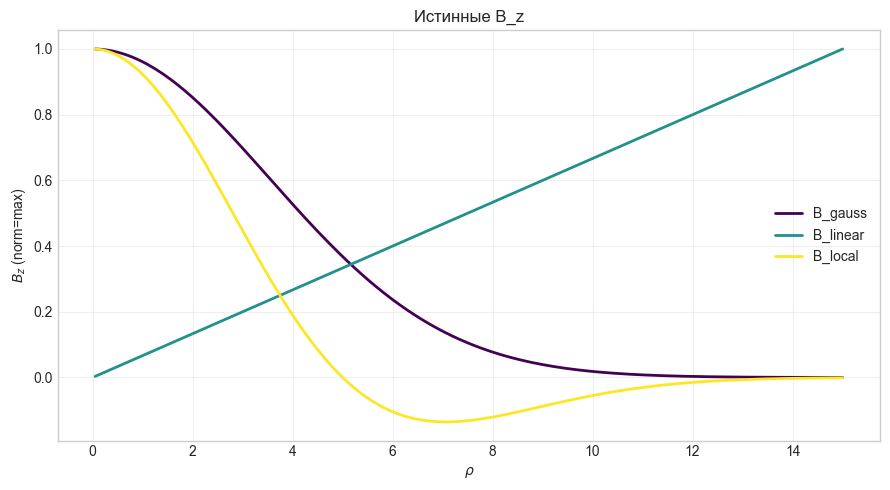

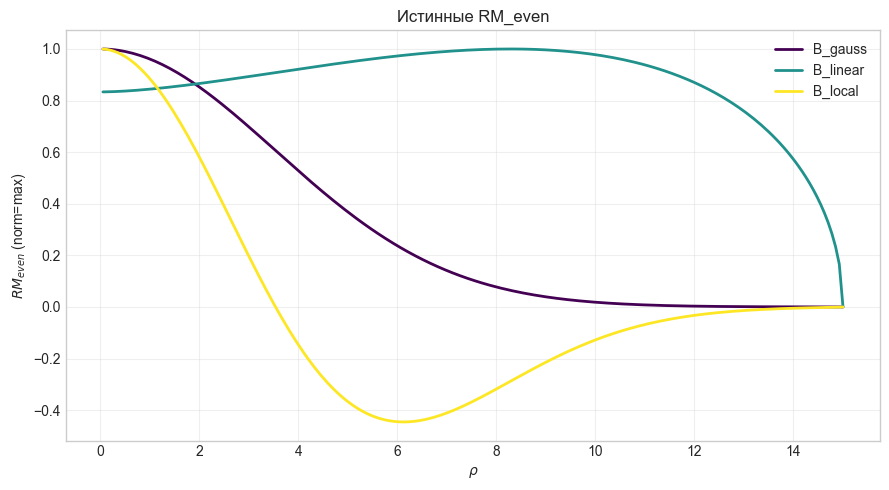

Загружено запусков: ['B_gauss', 'B_linear', 'B_local']


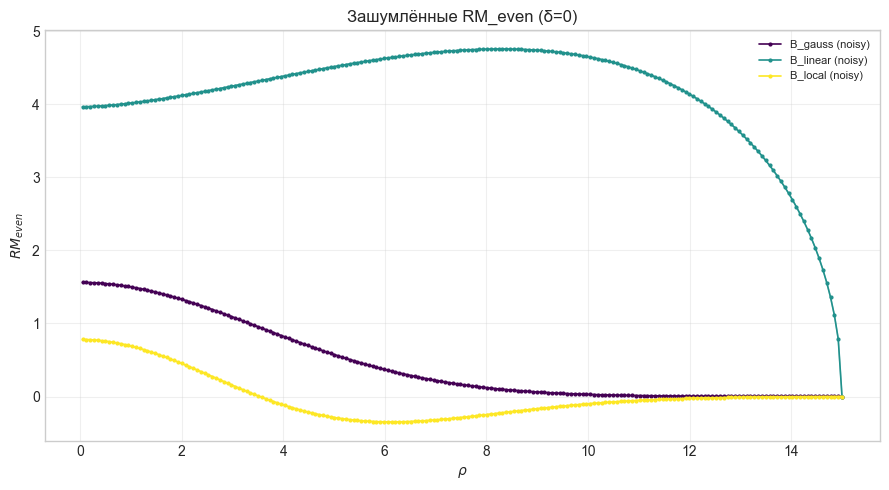

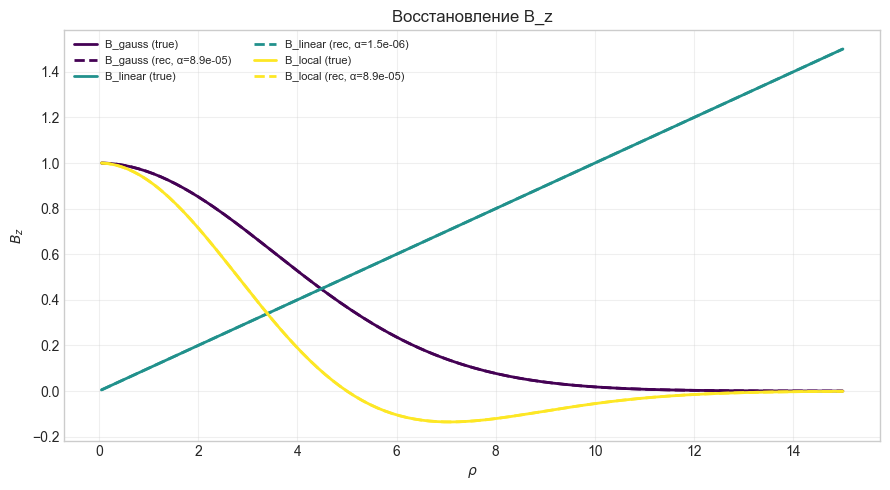

Загружено запусков: ['B_gauss', 'B_linear', 'B_local']


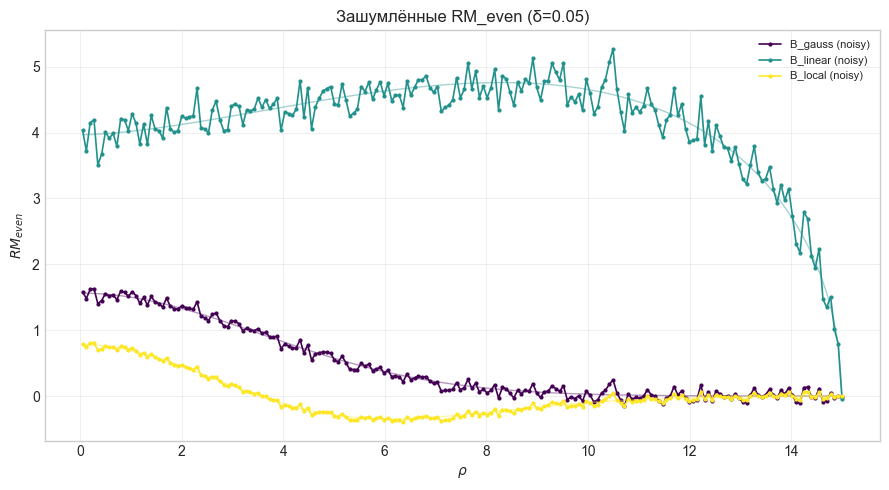

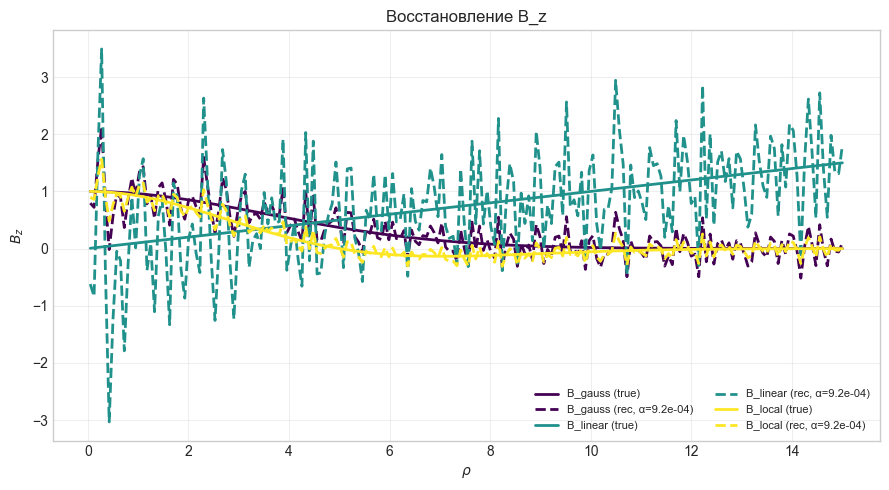

Загружено запусков: ['B_gauss', 'B_linear', 'B_local']


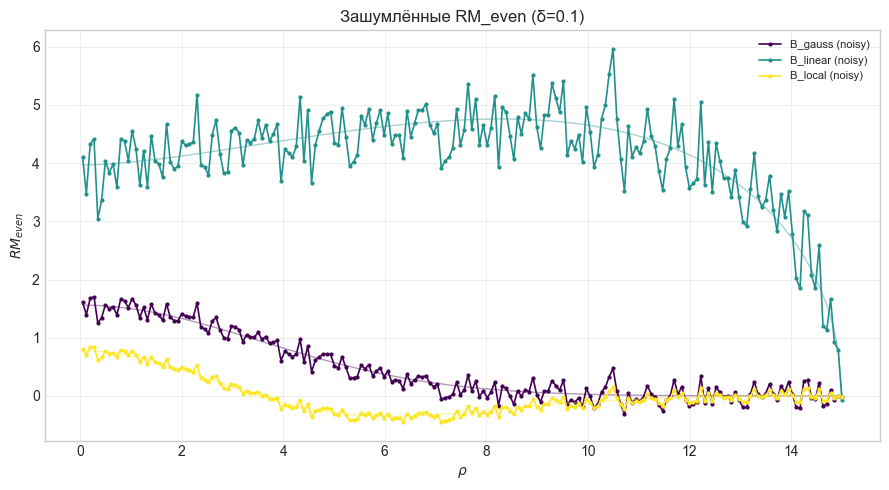

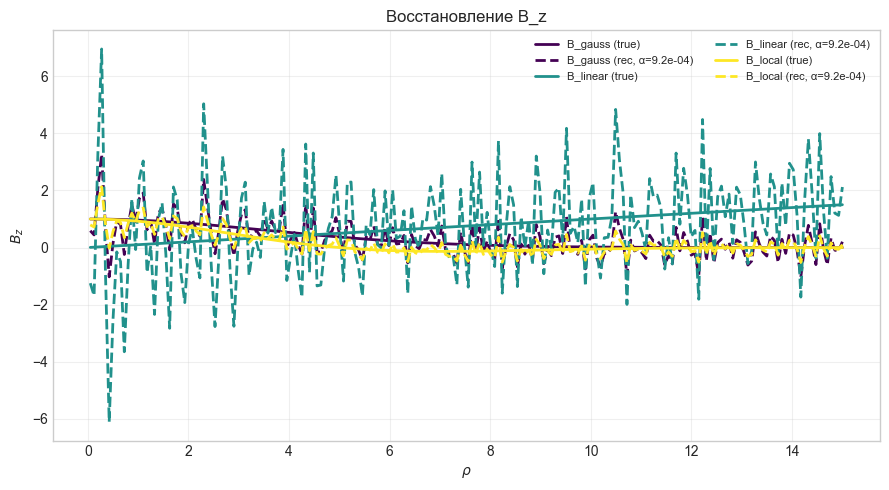

Загружено запусков: ['B_gauss', 'B_linear', 'B_local']


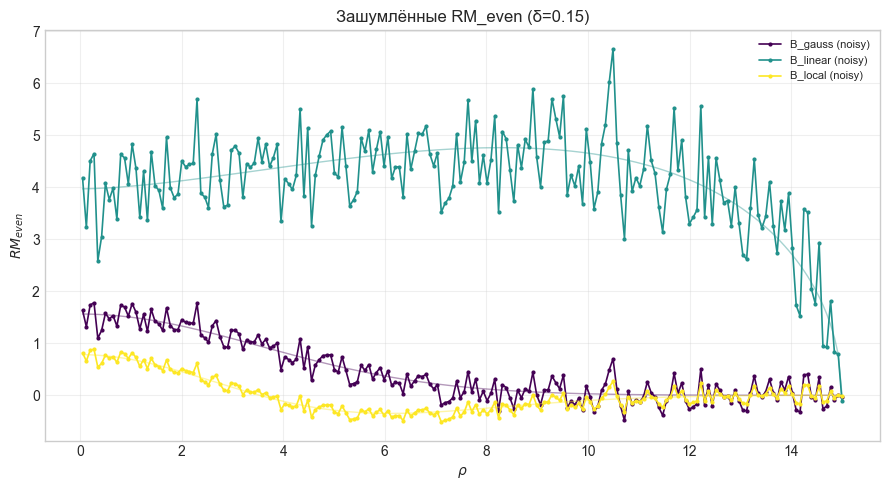

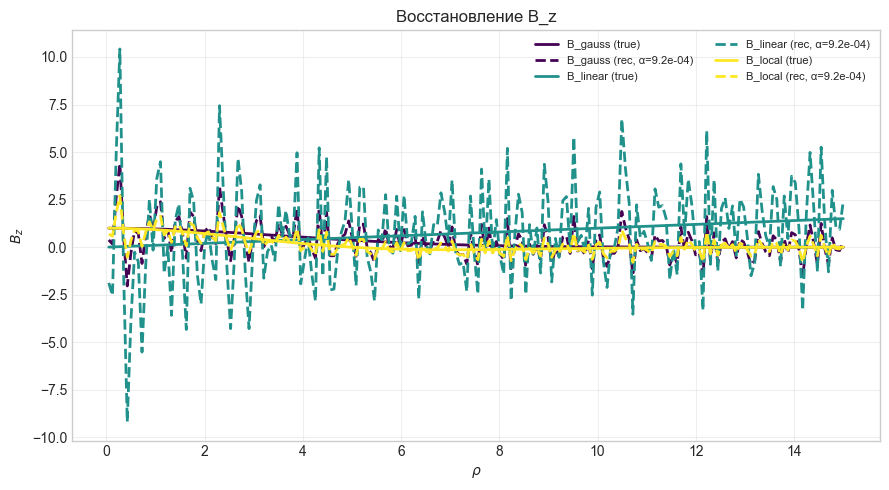

Загружено запусков: ['B_gauss', 'B_linear', 'B_local']


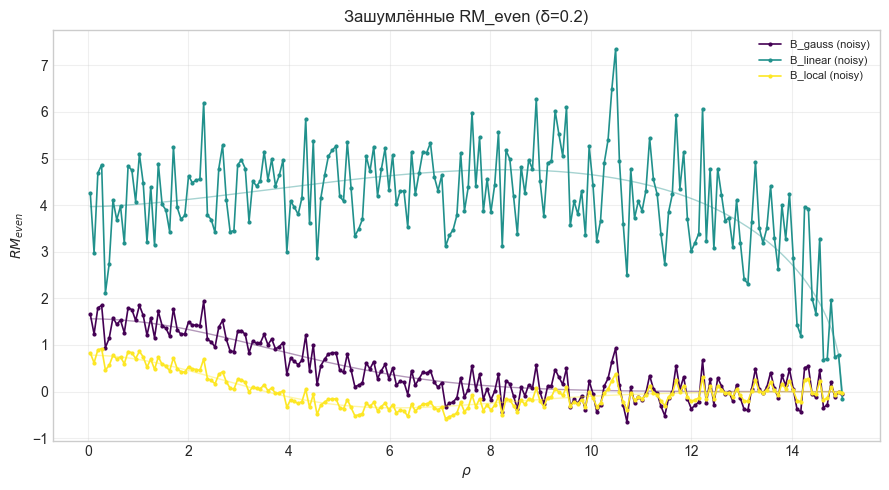

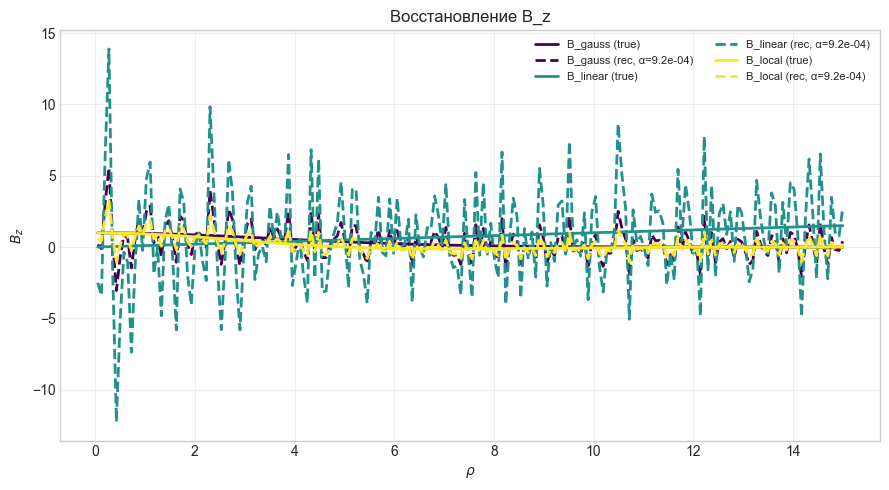

In [25]:
# ==============================================================================
# ЧТЕНИЕ ВСЕХ ЗАПУСКОВ И СВОДНЫЕ ГРАФИКИ
# ==============================================================================

FILENAME = f"results/all_runs_var_with B_noise_{deltas[0]}.csv"
rho, runs = load_runs(FILENAME)

# 1) Все истинные B_z на одном графике
plot_all_true_fields(rho, runs, field_key='B_z_true',
                        ylabel=r'$B_z$',
                        title="Истинные B_z",
                        norm = "max")

# 2) Все RM_even (истинные) на одном графике
plot_all_rm(rho, runs, rm_key='RM_even_true',
            ylabel=r'$RM_{even}$',
            title="Истинные RM_even",
            norm = "max")

for REG_KIND in reg_kinds:
    for delta_tmp in deltas:
        FILENAME = f"results/all_runs_var_with B_noise_{delta_tmp}.csv"
        rho, runs = load_runs(FILENAME)
        print(f"Загружено запусков: {list(runs.keys())}")
        
        TYPE_NORM = None
        # 3) Все зашумлённые RM_even на одном графике
        plot_all_rm_noisy(rho, runs,
                        rm_noisy_key='RM_even_noisy',
                        rm_true_key='RM_even_true',
                        ylabel=r'$RM_{even}$',
                        title=f"Зашумлённые RM_even (δ={delta_tmp})",
                        norm = TYPE_NORM)

        # 4) Все восстановленные B_z + истинные — на одном графике
        plot_all_recovered_fields(rho, runs,
                                true_key='B_z_true',
                                rec_key='B_z_rec',
                                ylabel=r'$B_z$',
                                title="Восстановление B_z",
                                norm = TYPE_NORM)

5

def B_z_gauss(rho, B0=1.0, rho_scale=5.0):
    return B0 * np.exp(-(rho / rho_scale)**2)

def B_z_local(rho, B0=1.0, rho_scale=5.0):
    # локальный горб со сменой знака — аналог A_phi = ρ·e^(-ρ/L)
    return B0 * (1 - (rho / rho_scale)**2) * np.exp(-(rho / rho_scale)**2)

def B_z_linear(rho, B0=0.1):
    return B0 * rho

variants_B = {
    "B_gauss":  B_z_gauss,
    "B_local":  B_z_local,
    "B_linear": B_z_linear,
}

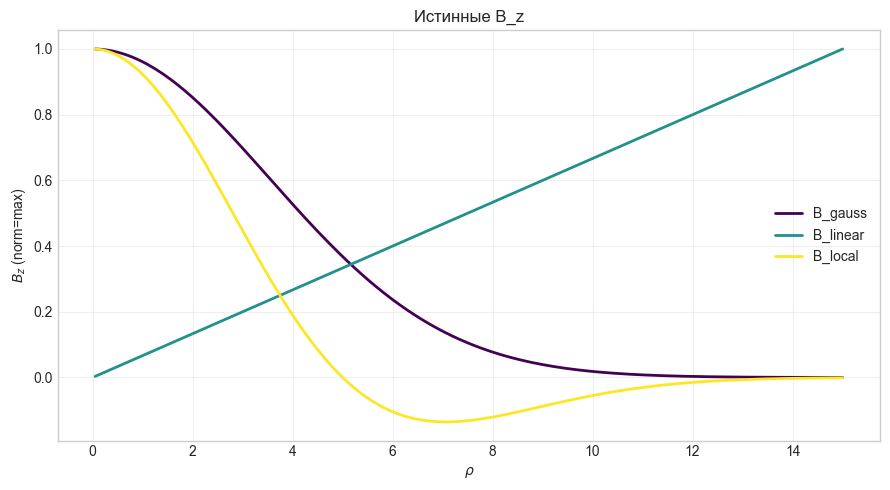

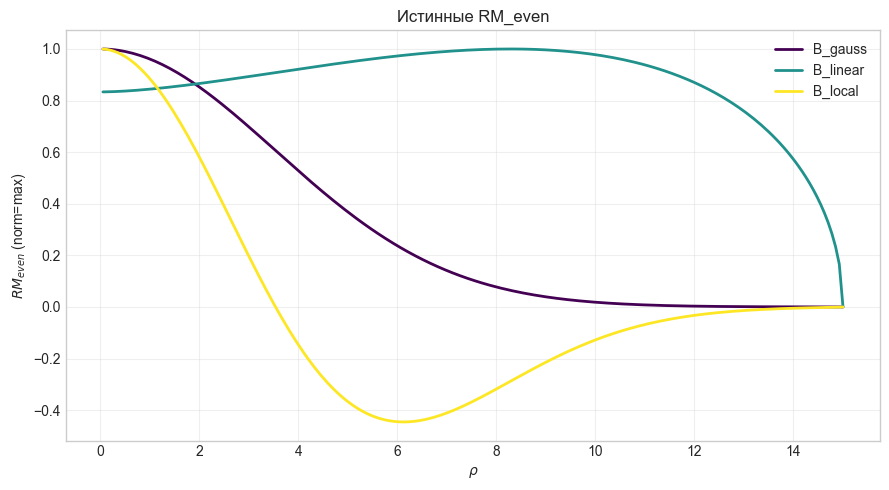

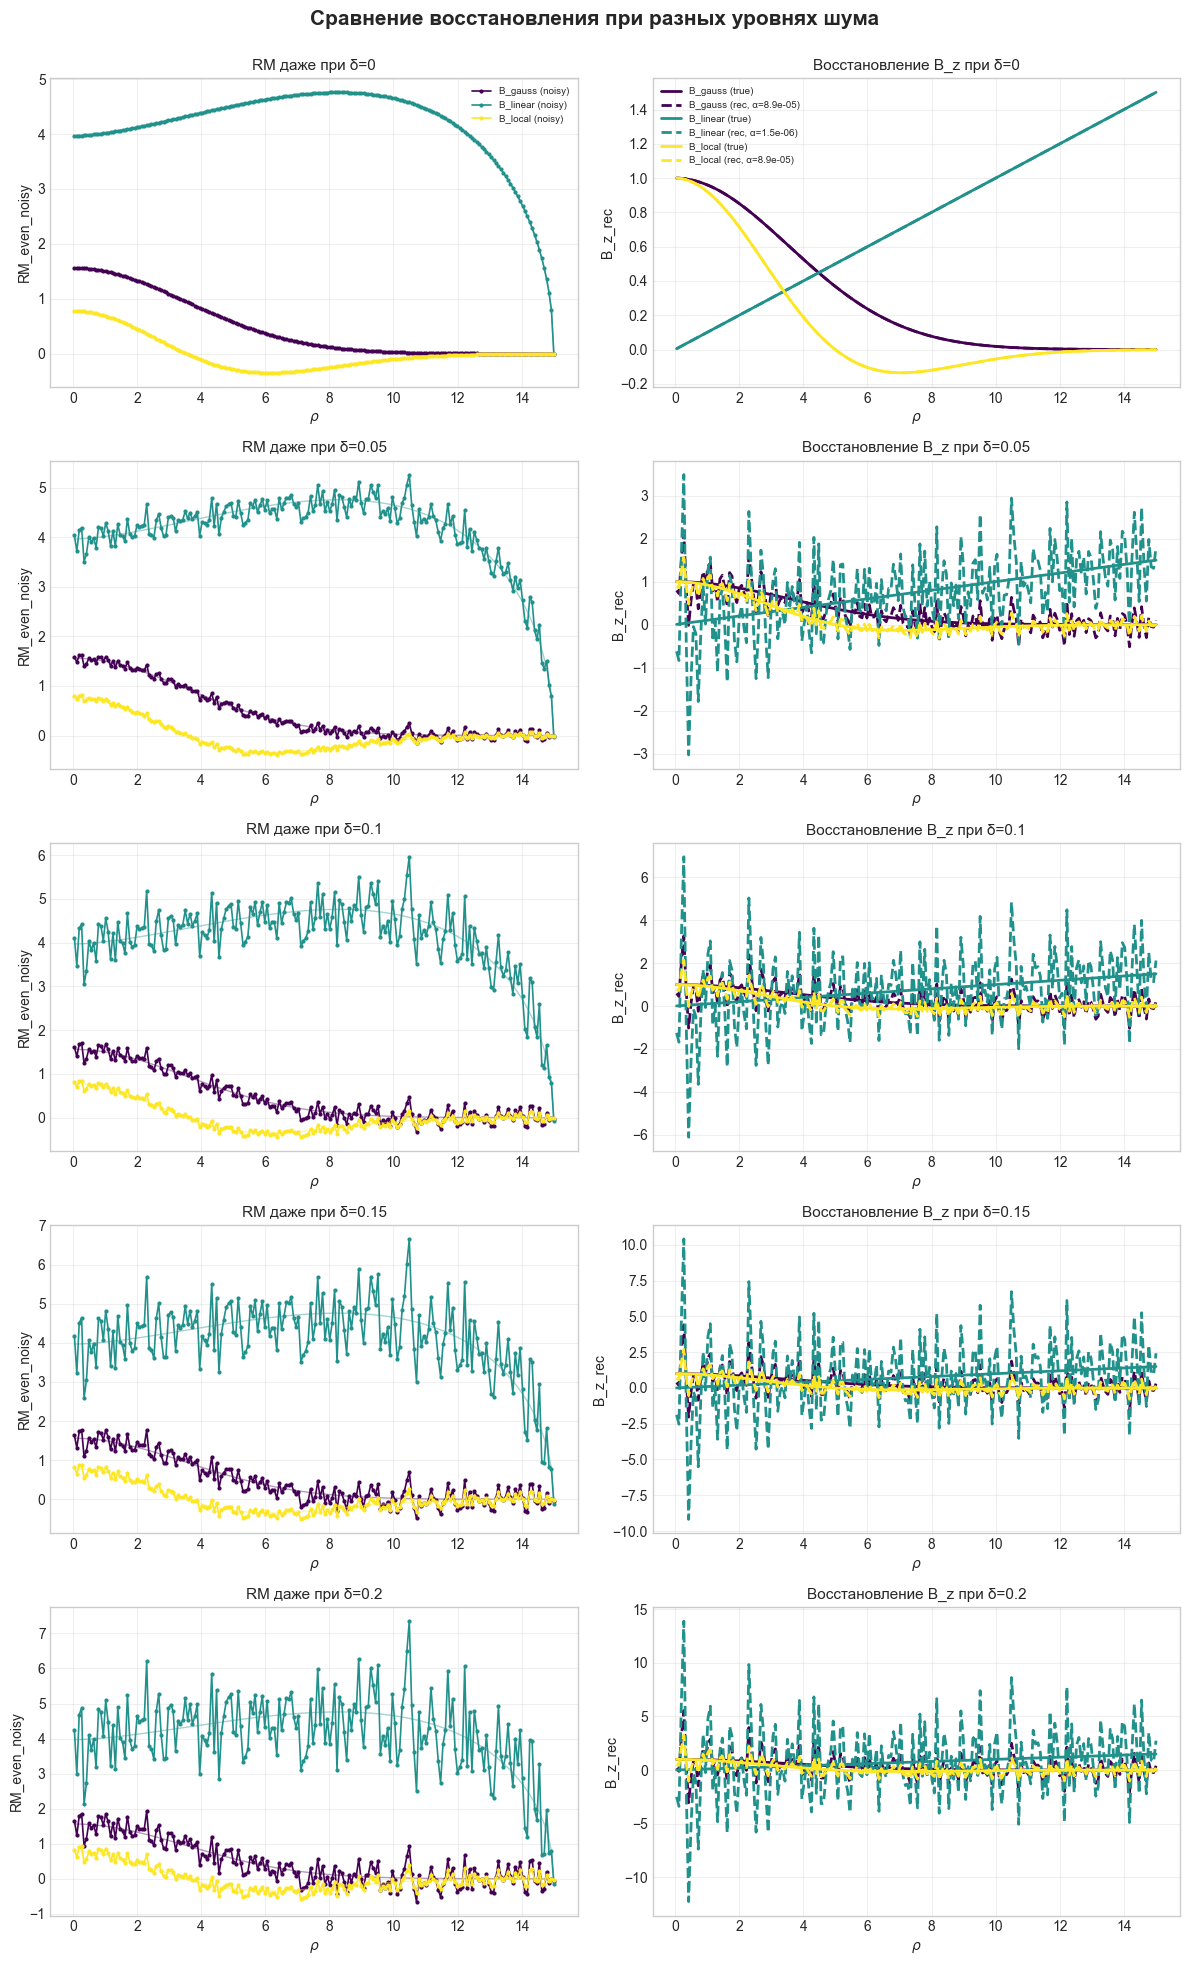

In [13]:
from methods import plot_noise_sweep_grid
csv_paths = {}

for delta_tmp in deltas:
    filename = f"results/all_runs_var_with B_noise_{delta_tmp}.csv"
    csv_paths[delta_tmp] = filename
    
rho, runs = load_runs(csv_paths[deltas[0]])
# 1) Все истинные B_z на одном графике
plot_all_true_fields(rho, runs, field_key='B_z_true',
                        ylabel=r'$B_z$',
                        title="Истинные B_z",
                        norm = "max")

# 2) Все RM_even (истинные) на одном графике
plot_all_rm(rho, runs, rm_key='RM_even_true',
            ylabel=r'$RM_{even}$',
            title="Истинные RM_even",
            norm = "max")

plot_noise_sweep_grid(
    csv_paths,
    deltas=sorted(csv_paths.keys()),
    norm= None, # None, "max"
    title="Сравнение восстановления при разных уровнях шума",
)
